In [40]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /home/ibm-user/Z-Guard-AI
Files: ['tests', 'docs', 'z_guard_anomaly_report.csv', 'scripts', 'z_guard_anomaly_chart.html', 'app.py', 'data', 'src', 'run.sh', '.ipynb_checkpoints', 'README.md', 'requirements.txt', 'run.ps1']


In [41]:
if os.path.exists("requirements.txt"):
    with open("requirements.txt", encoding="utf-8") as f:
        print(f.read())
else:
    print("No requirements.txt found in this directory.")

# Z-Guard AI Dependencies
# Compatible with x86_64 and s390x (IBM LinuxONE / zSystems)

streamlit>=1.35.0,<2.0.0
pandas>=2.1.0,<3.0.0
numpy>=1.26.0,<3.0.0
scikit-learn>=1.4.0,<2.0.0
plotly>=5.20.0,<6.0.0
psutil>=5.9.0,<7.0.0
pytest>=8.0.0,<9.0.0



In [42]:
import os

os.listdir("/home/ibm-user/Z-Guard-AI")


['tests',
 'docs',
 'z_guard_anomaly_report.csv',
 'scripts',
 'z_guard_anomaly_chart.html',
 'app.py',
 'data',
 'src',
 'run.sh',
 '.ipynb_checkpoints',
 'README.md',
 'requirements.txt',
 'run.ps1']

In [43]:
!cat /home/ibm-user/Z-Guard-AI/requirements.txt

# Z-Guard AI Dependencies
# Compatible with x86_64 and s390x (IBM LinuxONE / zSystems)

streamlit>=1.35.0,<2.0.0
pandas>=2.1.0,<3.0.0
numpy>=1.26.0,<3.0.0
scikit-learn>=1.4.0,<2.0.0
plotly>=5.20.0,<6.0.0
psutil>=5.9.0,<7.0.0
pytest>=8.0.0,<9.0.0


In [44]:
!head -60 /home/ibm-user/Z-Guard-AI/app.py

"""
Z-Guard AI: Real-Time Server Anomaly Detection Dashboard
IBM Z Datathon 2026

Modern, accessible, enterprise-grade server monitoring dashboard powered by
Scikit-Learn Isolation Forest and Plotly.
"""

import os
import sys
from datetime import datetime
import pandas as pd
import streamlit as st

# Ensure project root is accessible
sys.path.insert(0, os.path.abspath(os.path.dirname(__file__)))

from src.config import (
    APP_NAME,
    APP_SUBTITLE,
    COLOR_ANOMALY,
    COLOR_IBM_BLUE,
    COLOR_NORMAL,
    COLOR_WARNING,
    DEFAULT_CONTAMINATION,
    DEFAULT_N_ESTIMATORS,
    FEATURE_COLUMNS,
    HACKATHON_EVENT,
    METRIC_LABELS,
    METRIC_UNITS,
    PLATFORM_TARGET,
)
from src.data_loader import (
    generate_synthetic_telemetry,
    validate_and_clean_data,
)
from src.detector import AnomalyDetector
from src.metrics_collector import SystemMetricsCollector
from src.visualizer import (
    create_radar_attribution,
    create_scatter_correlation,
    create_synchronized_metr

In [45]:
import os

project = "/home/ibm-user/Z-Guard-AI"

for root, dirs, files in os.walk(project):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".git"]]
    level = root.replace(project, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for file in files:
            print("  " * (level + 1) + file)

Z-Guard-AI/
  z_guard_anomaly_report.csv
  z_guard_anomaly_chart.html
  app.py
  run.sh
  README.md
  requirements.txt
  run.ps1
  tests/
    test_metrics.py
    __init__.py
    test_data_loader.py
    test_detector.py
  docs/
    LINUXONE_DEPLOYMENT.md
  scripts/
    generate_datasets.py
    verify_app_headless.py
  data/
    clean_baseline_metrics.csv
    test_synthetic_scenarios.csv
    sample_server_metrics.csv
  src/
    config.py
    __init__.py
    visualizer.py
    detector.py
    data_loader.py
    metrics_collector.py
  .ipynb_checkpoints/
    z_guard_anomaly_chart-checkpoint.html
    app-checkpoint.py


In [46]:
%pip show streamlit pandas numpy scikit-learn plotly psutil

Name: pandas
Version: 3.0.6
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

 Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
 All rights reserved.

 Copyright (c) 2011-2026, Open source contributors.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are met:

 * Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

 * Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

 * Neither the name of the copyright holder nor the names of its
   contribut

In [47]:
%pip install plotly



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [48]:
from src.data_loader import generate_synthetic_telemetry
from src.detector import AnomalyDetector

df = generate_synthetic_telemetry(1000)
detector = AnomalyDetector()
detector.fit(df)
detector.predict(df)

,timestamp,cpu_pct,memory_pct,disk_pct,network_mbps,ground_truth_scenario,anomaly,prediction_label,raw_decision_score,anomaly_score,culprit_metric,anomaly_reason,severity,mitigation_action
0,2026-10-16 15:40:14,29.74,50.20,36.97,85.66,Normal Operation,False,Normal,0.2110,7.4,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
1,2026-10-16 15:41:14,27.67,49.30,38.57,105.33,Normal Operation,False,Normal,0.2197,6.7,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
2,2026-10-16 15:42:14,30.57,47.63,36.62,114.19,Normal Operation,False,Normal,0.2355,5.6,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
3,2026-10-16 15:43:14,33.78,46.27,38.07,156.43,Normal Operation,False,Normal,0.2379,5.4,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
4,2026-10-16 15:44:14,27.78,49.01,33.31,133.29,Normal Operation,False,Normal,0.2348,5.6,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2026-10-17 08:15:14,26.41,49.31,39.23,117.24,Normal Operation,False,Normal,0.2200,6.7,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
996,2026-10-17 08:16:14,33.84,47.18,39.77,80.15,Normal Operation,False,Normal,0.1970,8.6,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
997,2026-10-17 08:17:14,29.94,45.52,35.27,112.60,Normal Operation,False,Normal,0.2393,5.4,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.
998,2026-10-17 08:18:14,25.85,47.02,40.00,148.76,Normal Operation,False,Normal,0.2222,6.5,None (Healthy),Operational metrics within expected baseline d...,NORMAL,No action needed. System operating smoothly.


In [49]:
import os
import sys

PROJECT_DIR = "/home/ibm-user/Z-Guard-AI"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("Project files:", os.listdir(PROJECT_DIR))

os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

print("Current directory:", os.getcwd())
print("src exists:", os.path.isdir("src"))

Project exists: True
Project files: ['tests', 'docs', 'z_guard_anomaly_report.csv', 'scripts', 'z_guard_anomaly_chart.html', 'app.py', 'data', 'src', 'run.sh', '.ipynb_checkpoints', 'README.md', 'requirements.txt', 'run.ps1']
Current directory: /home/ibm-user/Z-Guard-AI
src exists: True


In [50]:
print(os.listdir("src"))

['config.py', '__pycache__', '__init__.py', 'visualizer.py', 'detector.py', 'data_loader.py', 'metrics_collector.py']


In [51]:
from src.data_loader import generate_synthetic_telemetry
from src.detector import AnomalyDetector

print("Imports successful!")

Imports successful!


In [52]:
from src.data_loader import generate_synthetic_telemetry

df = generate_synthetic_telemetry(1000)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 6)


,timestamp,cpu_pct,memory_pct,disk_pct,network_mbps,ground_truth_scenario
0,2026-10-16 15:40:15,29.74,50.20,36.97,85.66,Normal Operation
1,2026-10-16 15:41:15,27.67,49.30,38.57,105.33,Normal Operation
2,2026-10-16 15:42:15,30.57,47.63,36.62,114.19,Normal Operation
3,2026-10-16 15:43:15,33.78,46.27,38.07,156.43,Normal Operation
4,2026-10-16 15:44:15,27.78,49.01,33.31,133.29,Normal Operation


In [53]:
from src.detector import AnomalyDetector

detector = AnomalyDetector()
print(detector)

In [54]:
print([m for m in dir(detector) if not m.startswith("_")])

['baseline_stats', 'contamination', 'fit', 'get_model_summary', 'is_fitted', 'model', 'n_estimators', 'predict', 'random_state', 'scaler']


In [55]:
import inspect
print(inspect.getsource(AnomalyDetector))

class AnomalyDetector:
    """
    Production-ready Isolation Forest wrapper for server telemetry anomaly detection.
    Performs unsupervised outlier scoring and multi-metric root cause attribution.
    """

    def __init__(
        self,
        contamination: float = DEFAULT_CONTAMINATION,
        n_estimators: int = DEFAULT_N_ESTIMATORS,
        random_state: int = DEFAULT_RANDOM_STATE,
    ):
        self.contamination = contamination
        self.n_estimators = n_estimators
        self.random_state = random_state
        self.scaler = RobustScaler()
        self.model = IsolationForest(
            contamination=self.contamination,
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=-1
        )
        self.is_fitted = False
        self.baseline_stats: Dict[str, Dict[str, float]] = {}

    def fit(self, df: pd.DataFrame) -> "AnomalyDetector":
        """
        Fits the scaler and Isolation Forest model on historical or 

In [56]:

from src.data_loader import generate_synthetic_telemetry

df = generate_synthetic_telemetry(1000)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1000, 6)


,timestamp,cpu_pct,memory_pct,disk_pct,network_mbps,ground_truth_scenario
0,2026-10-16 15:40:15,29.74,50.20,36.97,85.66,Normal Operation
1,2026-10-16 15:41:15,27.67,49.30,38.57,105.33,Normal Operation
2,2026-10-16 15:42:15,30.57,47.63,36.62,114.19,Normal Operation
3,2026-10-16 15:43:15,33.78,46.27,38.07,156.43,Normal Operation
4,2026-10-16 15:44:15,27.78,49.01,33.31,133.29,Normal Operation


In [57]:

from src.detector import AnomalyDetector

detector = AnomalyDetector()
detector.fit(df)

print("Model trained successfully!")
print(detector.get_model_summary())


Model trained successfully!
{'model_type': 'Isolation Forest (Ensemble Tree-based)', 'n_estimators': 150, 'contamination': 0.05, 'random_state': 42, 'is_fitted': True, 'monitored_features': ['cpu_pct', 'memory_pct', 'disk_pct', 'network_mbps'], 'baseline_stats': {'cpu_pct': {'mean': 31.3581, 'median': 29.520000000000003, 'std': 15.74065279270019, 'q25': 21.697499999999998, 'q75': 36.815}, 'memory_pct': {'mean': 47.457910000000005, 'median': 45.64, 'std': 10.19427555965043, 'q25': 41.79, 'q75': 49.3}, 'disk_pct': {'mean': 37.42181999999999, 'median': 35.215, 'std': 12.441705016247225, 'q25': 32.3325, 'q75': 38.325}, 'network_mbps': {'mean': 144.52249, 'median': 124.41499999999999, 'std': 142.95930833961404, 'q25': 79.97749999999999, 'q75': 168.81}}}


In [58]:

results = detector.predict(df)

print("Total records:", len(results))
print("Anomalies detected:", results["anomaly"].sum())

display(
    results[
        ["prediction_label", "anomaly_score", "culprit_metric",
         "severity", "anomaly_reason"]
    ].head(20)
)


Total records: 1000
Anomalies detected: 50


,prediction_label,anomaly_score,culprit_metric,severity,anomaly_reason
0,Normal,7.4,None (Healthy),NORMAL,Operational metrics within expected baseline d...
1,Normal,6.7,None (Healthy),NORMAL,Operational metrics within expected baseline d...
2,Normal,5.6,None (Healthy),NORMAL,Operational metrics within expected baseline d...
3,Normal,5.4,None (Healthy),NORMAL,Operational metrics within expected baseline d...
4,Normal,5.6,None (Healthy),NORMAL,Operational metrics within expected baseline d...
5,Normal,6.8,None (Healthy),NORMAL,Operational metrics within expected baseline d...
6,Normal,6.4,None (Healthy),NORMAL,Operational metrics within expected baseline d...
7,Normal,6.2,None (Healthy),NORMAL,Operational metrics within expected baseline d...
8,Normal,7.8,None (Healthy),NORMAL,Operational metrics within expected baseline d...
9,Normal,8.0,None (Healthy),NORMAL,Operational metrics within expected baseline d...


In [59]:

import plotly.express as px

fig = px.scatter(
    results.reset_index(),
    x=results.index,
    y="anomaly_score",
    color="prediction_label",
    hover_data=["culprit_metric", "severity"],
    title="Z-Guard AI — Server Anomaly Detection"
)

fig.show()


In [60]:

import plotly.express as px
from IPython.display import display

fig = px.scatter(
    results.reset_index(),
    x="index",
    y="anomaly_score",
    color="prediction_label",
    hover_data=["culprit_metric", "severity"],
    title="Z-Guard AI — Server Anomaly Detection"
)

display(fig)


In [61]:

import plotly.io as pio

print("Plotly version:", px.__version__ if hasattr(px, "__version__") else "installed")
print("Available renderers:", pio.renderers)
print("Current renderer:", pio.renderers.default)


Plotly version: installed
Available renderers: Renderers configuration
-----------------------
    Default renderer: 'plotly_mimetype'
    Available renderers:
        ['plotly_mimetype', 'jupyterlab', 'nteract', 'vscode',
         'notebook', 'notebook_connected', 'kaggle', 'azure', 'colab',
         'cocalc', 'databricks', 'json', 'png', 'jpeg', 'jpg', 'svg',
         'pdf', 'browser', 'firefox', 'chrome', 'chromium', 'iframe',
         'iframe_connected', 'sphinx_gallery', 'sphinx_gallery_png']

Current renderer: plotly_mimetype


In [62]:

fig.write_html("z_guard_anomaly_chart.html")
print("Chart saved successfully.")


Chart saved successfully.


In [63]:
0
print("Rows:", len(results))
print("Anomaly scores:")
display(results["anomaly_score"].describe())
print("Labels:")
display(results["prediction_label"].value_counts())


Rows: 1000
Anomaly scores:


count    1000.000000
mean       13.421000
std        14.790857
min         5.000000
25%         6.300000
50%         7.800000
75%        10.900000
max        81.300000
Name: anomaly_score, dtype: float64

Labels:


prediction_label
Normal     950
Anomaly     50
Name: count, dtype: int64

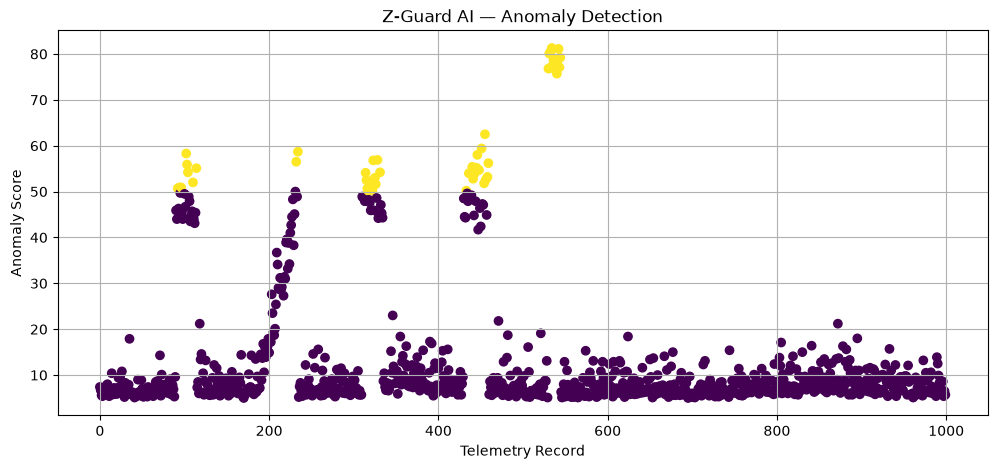

In [64]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.scatter(
    range(len(results)),
    results["anomaly_score"],
    c=(results["prediction_label"] == "Anomaly").astype(int)
)
plt.xlabel("Telemetry Record")
plt.ylabel("Anomaly Score")
plt.title("Z-Guard AI — Anomaly Detection")
plt.grid(True)
plt.show()


🛡️ Z-GUARD AI MONITORING DASHBOARD
Total records:     1000
Normal records:    950
Anomalies detected:50
Anomaly rate:      5.0%

Severity breakdown:


,Count
severity,
NORMAL,950
CRITICAL,38
WARNING,12


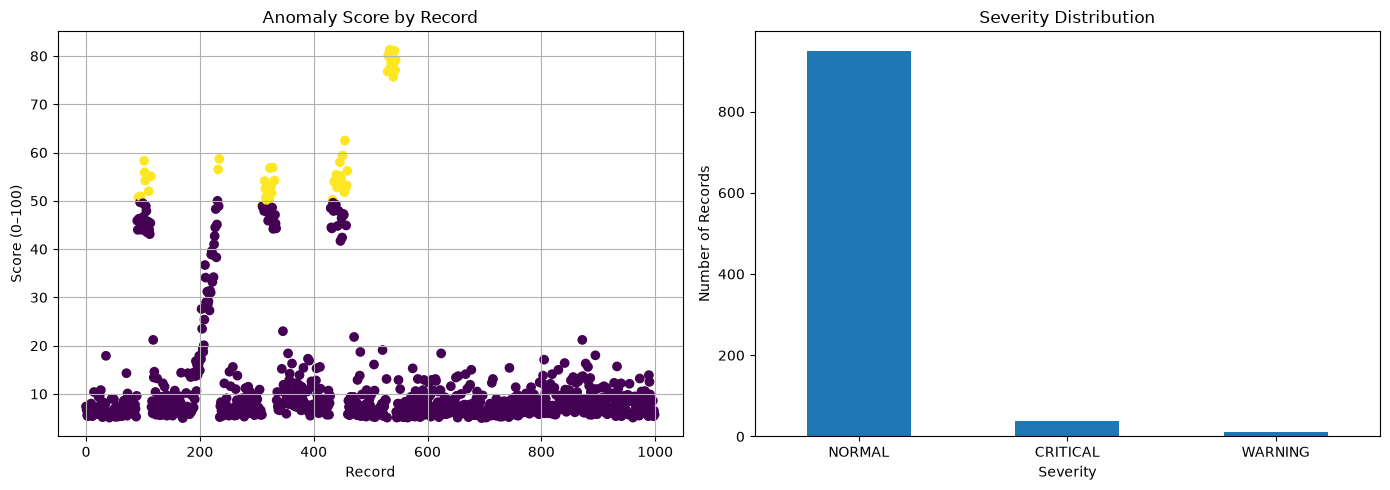

In [65]:


import matplotlib.pyplot as plt
import pandas as pd

# Summary metrics
total = len(results)
anomalies = int(results["anomaly"].sum())
normal = total - anomalies

print("🛡️ Z-GUARD AI MONITORING DASHBOARD")
print("=" * 40)
print(f"Total records:     {total}")
print(f"Normal records:    {normal}")
print(f"Anomalies detected:{anomalies}")
print(f"Anomaly rate:      {anomalies / total * 100:.1f}%")

print("\nSeverity breakdown:")
display(results["severity"].value_counts().to_frame("Count"))

# Plot anomaly scores
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    range(total),
    results["anomaly_score"],
    c=(results["prediction_label"] == "Anomaly").astype(int)
)
axes[0].set_title("Anomaly Score by Record")
axes[0].set_xlabel("Record")
axes[0].set_ylabel("Score (0–100)")
axes[0].grid(True)

results["severity"].value_counts().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Severity Distribution")
axes[1].set_xlabel("Severity")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Available monitoring metrics: ['cpu_pct', 'memory_pct', 'disk_pct', 'network_mbps']


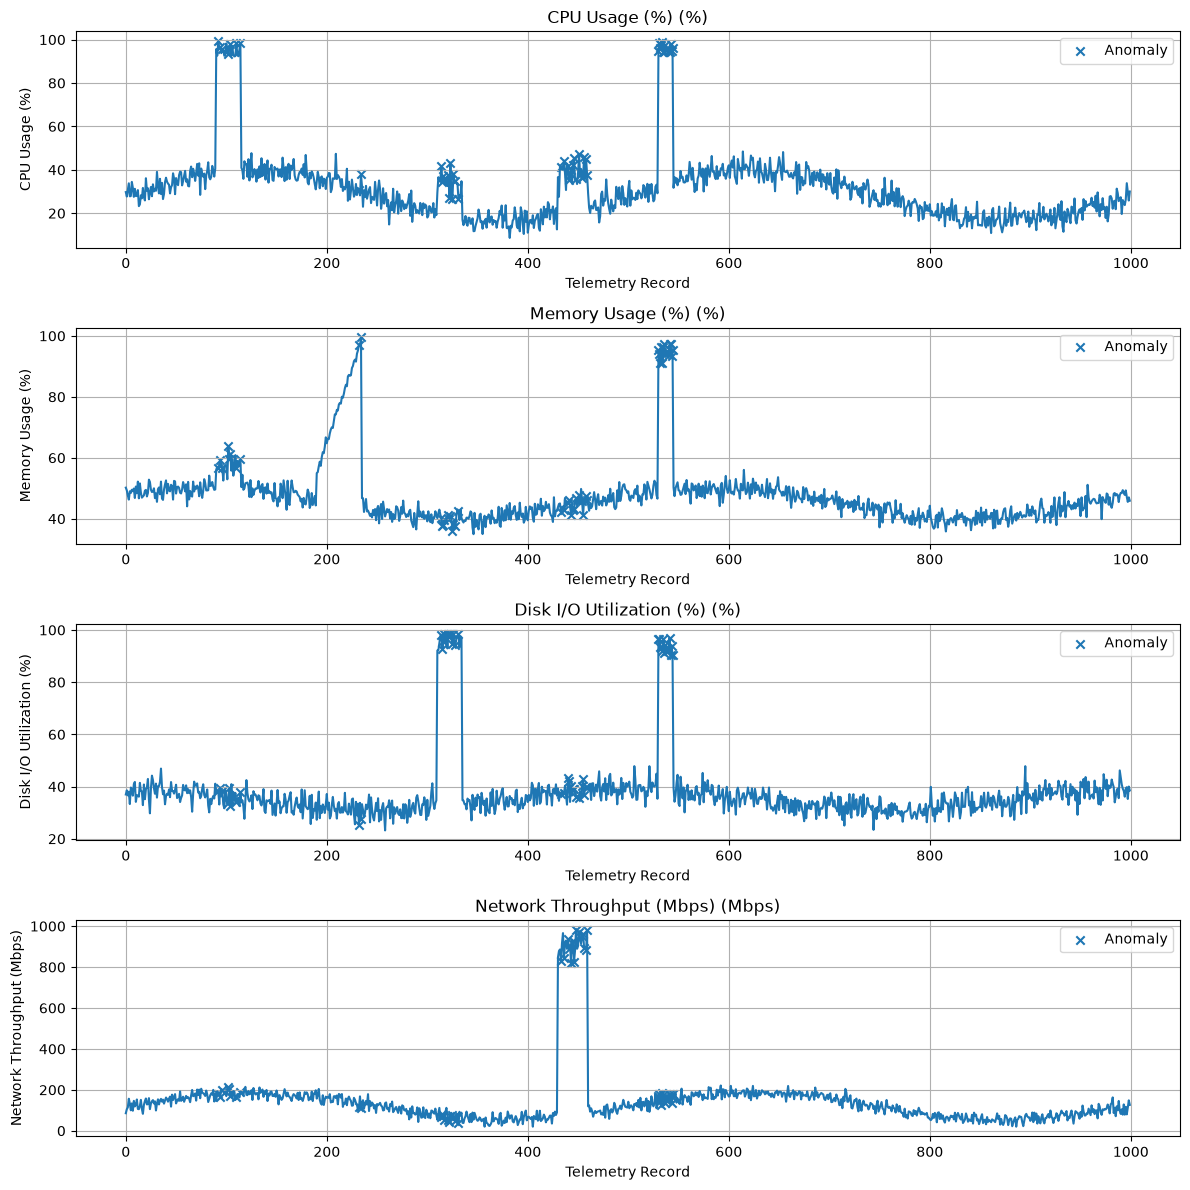

In [66]:

import matplotlib.pyplot as plt

from src.config import FEATURE_COLUMNS, METRIC_LABELS, METRIC_UNITS

print("Available monitoring metrics:", FEATURE_COLUMNS)

# Plot each metric using your project's actual feature names
fig, axes = plt.subplots(
    len(FEATURE_COLUMNS), 1,
    figsize=(12, 3 * len(FEATURE_COLUMNS))
)

if len(FEATURE_COLUMNS) == 1:
    axes = [axes]

for ax, col in zip(axes, FEATURE_COLUMNS):
    ax.plot(results[col].reset_index(drop=True))
    
    # Highlight anomalous records
    anomaly_positions = [
        i for i, flag in enumerate(results["anomaly"]) if flag
    ]
    ax.scatter(
        anomaly_positions,
        results[col].iloc[anomaly_positions],
        label="Anomaly",
        marker="x"
    )
    
    label = METRIC_LABELS.get(col, col)
    unit = METRIC_UNITS.get(col, "")
    
    ax.set_title(f"{label} ({unit})")
    ax.set_xlabel("Telemetry Record")
    ax.set_ylabel(label)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()



In [67]:

# Filter records identified as anomalies
anomaly_report = results.loc[
    results["anomaly"],
    [
        "anomaly_score",
        "severity",
        "culprit_metric",
        "anomaly_reason",
        "mitigation_action"
    ]
].sort_values("anomaly_score", ascending=False)

print("🛡️ Z-GUARD AI — ANOMALY INVESTIGATION REPORT")
print("=" * 55)
print("Total anomalies:", len(anomaly_report))

display(anomaly_report.head(20))


🛡️ Z-GUARD AI — ANOMALY INVESTIGATION REPORT
Total anomalies: 50


,anomaly_score,severity,culprit_metric,anomaly_reason,mitigation_action
534,81.3,CRITICAL,Disk I/O Utilization (%),Disk I/O Utilization (%) spiked to 92.0% (4.4σ...,Analyze disk I/O using `iotop -o` or `iostat -...
542,81.1,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 97.3% (4.9σ deviati...,Verify memory leak via `free -m` and process m...
533,80.7,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 96.5% (4.8σ deviati...,Verify memory leak via `free -m` and process m...
531,80.1,CRITICAL,Disk I/O Utilization (%),Disk I/O Utilization (%) spiked to 96.7% (4.8σ...,Analyze disk I/O using `iotop -o` or `iostat -...
544,79.2,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 95.3% (4.7σ deviati...,Verify memory leak via `free -m` and process m...
537,78.8,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 94.0% (4.6σ deviati...,Verify memory leak via `free -m` and process m...
536,78.7,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 97.2% (4.9σ deviati...,Verify memory leak via `free -m` and process m...
541,78.7,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 97.2% (4.9σ deviati...,Verify memory leak via `free -m` and process m...
535,77.5,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 96.3% (4.8σ deviati...,Verify memory leak via `free -m` and process m...
538,77.4,CRITICAL,Memory Usage (%),Memory Usage (%) spiked to 94.8% (4.6σ deviati...,Verify memory leak via `free -m` and process m...


In [68]:

report_path = "z_guard_anomaly_report.csv"

anomaly_report.to_csv(report_path, index=False)

print("Report saved to:", report_path)


Report saved to: z_guard_anomaly_report.csv
